# 2장 3강 · 객체 탐지와 세그멘테이션

**실습문제**

얼룩말 세 마리가 있는 사진에서 “얼룩말이 있다”, “세 마리가 어디에 있다”, “각각 어느 픽셀을 차지한다”에 답해 봅니다. 같은 사진이라도 질문마다 필요한 정답 데이터와 모델의 출력이 달라집니다.

| 구분 | 결과물 |
|---|---|
| 필수 1 | 객체별 좌표를 복원하고 박스 내부에서 해당 객체가 차지하는 면적을 계산한 표 |
| 필수 2 | 객체별 마스크와 클래스 마스크, 실제 검출 점수와 신뢰도 기준별 정답 대조표 |
| 독립 과제 | 고양이의 정답·예측 비교 그림, 별도 사진으로 마스크 층을 학습한 기록, 전후 평가와 결론 |

**실행 환경**　노트북 옆에 기존 `coco_sample.zip`을 두거나 첫 준비 셀의 `DATA_PATH`를 압축 해제 폴더로 바꾸세요. Python 3.10 이상에서 pandas, NumPy, Pillow, IPython, 호환되는 torch와 torchvision을 사용합니다. 제작 시 CPU에서 torch 2.6.0, torchvision 0.21.0으로 실행했습니다. 처음 실행하면 COCO 사전학습 Mask R-CNN 가중치 약 170 MB를 내려받습니다. 이후 같은 환경에서는 캐시를 사용합니다. 모든 실습은 CPU에서 진행할 수 있습니다.

**실험 조건**　데이터는 COCO val2017 배포본입니다. 이 안에서 12장을 수업용 미세조정에, 다른 8장을 평가에 배정합니다. 두 세트에는 서로 다른 이미지 ID를 사용합니다. 평가는 얼룩말·고양이·개의 개별 객체에 한정하며 세 클래스의 군중 주석이 있는 사진은 뽑지 않습니다. 검출 점수 기준은 0.50과 0.70, 동일 객체 판정의 박스 IoU 기준은 0.50, 예측 마스크의 픽셀 기준은 0.50으로 고정합니다.

**진행 순서**　아래 공통 준비 셀을 모두 실행한 후 필수 1, 필수 2, 독립 과제, 실습 마무리 순으로 진행하세요. 독립 과제는 공통 준비 셀만 실행한 새 커널에서도 풀 수 있습니다. 학습을 반복할 때에는 독립 과제에서 모델을 새로 만드는 셀부터 실행하세요.

In [1]:
# 필요한 경우에만 실행: %pip install pandas numpy pillow ipython torch torchvision
from pathlib import Path
from io import BytesIO
import zipfile
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw
from IPython.display import display

_candidates = [Path("coco_sample.zip"), Path("coco_dataset.zip")]
DATA_PATH = next((p for p in _candidates if p.exists()), _candidates[0])  # 압축 해제 폴더도 지정할 수 있습니다.
if not DATA_PATH.exists():
    raise FileNotFoundError("DATA_PATH를 실제 coco_sample.zip 또는 압축 해제 폴더 경로로 수정하세요.")
archive = zipfile.ZipFile(DATA_PATH) if DATA_PATH.is_file() else None
archive_names = set(archive.namelist()) if archive else None

def exists_in_data(relative_path):
    if archive is not None:
        return relative_path in archive_names
    return (DATA_PATH / relative_path).is_file()

def read_bytes(relative_path):
    if archive is not None:
        return archive.read(relative_path)
    return (DATA_PATH / relative_path).read_bytes()

def load_rgb(relative_path):
    with Image.open(BytesIO(read_bytes(relative_path))) as img:
        return img.convert("RGB")

def load_mask(relative_path):
    with Image.open(BytesIO(read_bytes(relative_path))) as img:
        return np.asarray(img.convert("L")).copy()

metadata = pd.read_csv(BytesIO(read_bytes("metadata.csv")))
objects = pd.read_csv(BytesIO(read_bytes("objects.csv")))
categories = pd.read_csv(BytesIO(read_bytes("categories.csv")))
metadata["file_exists"] = metadata["image_path"].map(exists_in_data)
available_images = metadata.loc[metadata["file_exists"]].copy()
available_objects = objects.loc[objects["image_id"].isin(available_images["image_id"])].copy()
print("메타데이터 이미지:", len(metadata))
print("실제 사용 가능한 이미지:", len(available_images))
print("파일이 없는 이미지:", (~metadata["file_exists"]).sum())
print("실제 이미지와 연결되는 객체 주석:", len(available_objects))
print("클래스 수:", len(categories))

메타데이터 이미지: 5000
실제 사용 가능한 이미지: 1974
파일이 없는 이미지: 3026
실제 이미지와 연결되는 객체 주석: 14589
클래스 수: 80


In [2]:
COLORS = [(230, 60, 60), (30, 180, 60), (45, 100, 240), (240, 160, 20), (190, 50, 200)]

def get_example(image_id):
    row = available_images.loc[available_images["image_id"] == image_id]
    if row.empty:
        raise ValueError(f"예제 이미지 {image_id}가 DATA_PATH에 없습니다.")
    img = load_rgb(row.iloc[0]["image_path"])
    rows = available_objects.loc[
        (available_objects["image_id"] == image_id) & (available_objects["iscrowd"] == 0)
    ].sort_values("annotation_id").copy()
    return img, rows

def draw_boxes(img, rows):
    canvas = img.copy()
    draw = ImageDraw.Draw(canvas)
    for i, (_, row) in enumerate(rows.iterrows()):
        color = COLORS[i % len(COLORS)]
        draw.rectangle(tuple(row[["xmin", "ymin", "xmax", "ymax"]]), outline=color, width=3)
        label = f"{row['class_name']} #{int(row['annotation_id'])}"
        x, y = int(row["xmin"]), max(0, int(row["ymin"]) - 15)
        draw.text((x, y), label, fill=color, stroke_width=1, stroke_fill="white")
    return canvas

def draw_masks(img, rows):
    canvas = np.asarray(img).astype(float).copy()
    for i, (_, row) in enumerate(rows.iterrows()):
        mask = load_mask(row["mask_path"])
        if mask.shape != (img.height, img.width):
            raise ValueError("이미지와 Mask의 가로·세로가 다릅니다.")
        selected = mask == 255
        canvas[selected] = 0.55 * canvas[selected] + 0.45 * np.array(COLORS[i % len(COLORS)])
    return Image.fromarray(canvas.astype("uint8"))

def show_panels(images, titles):
    # 가로로 너무 길어지지 않도록 패널마다 최대 480×360으로 표시합니다.
    previews = []
    for img in images:
        view = img.copy()
        view.thumbnail((480, 360))
        previews.append(view)
    w = max(v.width for v in previews)
    h = max(v.height for v in previews)
    panel = Image.new("RGB", (w * len(previews), h + 30), "white")
    draw = ImageDraw.Draw(panel)
    for i, (view, title) in enumerate(zip(previews, titles)):
        panel.paste(view, (i * w, 30))
        draw.text((i * w + 5, 8), title, fill="black")
    display(panel)

# 필수 실습은 얼룩말 3마리, 독립 과제는 개·고양이 등이 함께 있는 다른 이미지입니다.
EXAMPLE_ID = 11760
TASK_ID = 22892
example_image, example_objects = get_example(EXAMPLE_ID)
print("필수 예제 ID:", EXAMPLE_ID, "/ 크기(너비, 높이):", example_image.size)
print("과제 예제 ID:", TASK_ID)

필수 예제 ID: 11760 / 크기(너비, 높이): (640, 425)
과제 예제 ID: 22892


In [3]:
# 공통 제공 함수 · 모델 입력과 학습·평가 사진 선정
import torch
from torchvision.models.detection import maskrcnn_resnet50_fpn, MaskRCNN_ResNet50_FPN_Weights
from torchvision.transforms.functional import pil_to_tensor
from torchvision.ops import box_iou

torch.set_num_threads(2)
TARGETS = ["zebra", "cat", "dog"]
SCORES = (0.50, 0.70)
MASK_CUTOFF = 0.50
BOX_CUTOFF = 0.50
weights = MaskRCNN_ResNet50_FPN_Weights.DEFAULT
names = weights.meta["categories"]
def make_model():
    # 짧은 변 320, 긴 변 최대 512. CPU에서 한 번에 사진 한 장을 처리합니다.
    return maskrcnn_resnet50_fpn(weights=weights, min_size=320, max_size=512,
                                  box_score_thresh=0.30, box_detections_per_img=30)

def input_tensor(image):
    return pil_to_tensor(image).float() / 255

def select_ids():
    rng = np.random.default_rng(42)
    used = {EXAMPLE_ID, TASK_ID}
    train_ids, holdout_ids = [], [EXAMPLE_ID, TASK_ID]
    selected = available_objects[available_objects.class_name.isin(TARGETS)]
    crowd_ids = set(selected.loc[selected.iscrowd == 1, "image_id"])
    for name in TARGETS:
        pool = sorted(set(selected.loc[selected.class_name == name, "image_id"]) - used - crowd_ids)
        chosen = rng.choice(pool, size=6, replace=False).tolist()
        train_ids.extend(chosen[:4])
        holdout_ids.extend(chosen[4:])
        used.update(chosen)
    assert set(train_ids).isdisjoint(holdout_ids)
    assert not (set(holdout_ids) & crowd_ids)
    return train_ids, holdout_ids

In [4]:
# 공통 제공 함수 · 정답 텐서 구성과 마스크 층 학습
def train_target(rows):
    boxes = torch.tensor(rows[["xmin", "ymin", "xmax", "ymax"]].to_numpy(), dtype=torch.float32)
    labels = torch.tensor([names.index(name) for name in rows.class_name], dtype=torch.int64)
    masks = torch.from_numpy(np.stack([load_mask(p) == 255 for p in rows.mask_path])).to(torch.uint8)
    return {"boxes": boxes, "labels": labels, "masks": masks}

def tune_mask(model, ids):
    # 모델은 모든 손실을 계산하지만 이번 실습은 마지막 마스크 층만 갱신합니다.
    torch.manual_seed(42)
    model.requires_grad_(False)
    last = model.roi_heads.mask_predictor.mask_fcn_logits
    last.requires_grad_(True)
    optimizer = torch.optim.SGD(last.parameters(), lr=0.002)
    initial = last.weight.detach().clone()
    history = []
    model.train()
    for image_id in ids:
        image, rows = get_example(image_id)
        target = train_target(rows[rows.class_name.isin(TARGETS)])
        optimizer.zero_grad()
        losses = model([input_tensor(image)], [target])
        loss = losses["loss_mask"]
        loss.backward()
        optimizer.step()
        history.append({"image_id": image_id, "objects": len(target["labels"]), "loss_mask": loss.item()})
    model.eval()
    return pd.DataFrame(history), (last.weight.detach() - initial).abs().max().item()

In [5]:
# 공통 제공 함수 · 추론과 한 사진의 예측·정답 연결
@torch.inference_mode()
def predict(model, image):
    pred = model.eval()([input_tensor(image)])[0]
    records = []
    for i, label in enumerate(pred["labels"].tolist()):
        if names[label] in TARGETS:
            records.append({"rank": i + 1, "class_name": names[label], "score": pred["scores"][i].item(),
                            "box": pred["boxes"][i].cpu(), "mask": (pred["masks"][i,0] >= MASK_CUTOFF).cpu().numpy()})
    return records

def match_one_image(rows, predictions, cutoff):
    # 모델은 점수가 높은 순으로 출력합니다. 같은 이름의 미사용 정답 한 개만 연결합니다.
    gt = rows.loc[rows.class_name.isin(TARGETS)].set_index("annotation_id")
    unused = set(gt.index)
    records = []
    for p in predictions:
        if p["score"] < cutoff:
            continue
        candidates = sorted(i for i in unused if gt.loc[i, "class_name"] == p["class_name"])
        matched_id, overlap, mask_overlap = None, 0.0, np.nan
        if candidates:
            boxes = torch.tensor(gt.loc[candidates, ["xmin","ymin","xmax","ymax"]].to_numpy(dtype=float),
                                 dtype=torch.float32)
            values = box_iou(p["box"][None], boxes)[0]
            best = values.argmax().item()
            overlap = values[best].item()
            if overlap >= BOX_CUTOFF:
                matched_id = candidates[best]
                unused.remove(matched_id)
                true_mask = load_mask(gt.loc[matched_id, "mask_path"]) == 255
                inter = np.count_nonzero(true_mask & p["mask"])
                union = np.count_nonzero(true_mask | p["mask"])
                mask_overlap = inter / union
        records.append({"rank":p["rank"], "name":p["class_name"], "score":p["score"], "matched_id":matched_id,
                        "box_iou":overlap, "mask_iou":mask_overlap})
    return pd.DataFrame(records, columns=["rank","name","score","matched_id","box_iou","mask_iou"]), sorted(unused)

In [6]:
# 공통 제공 함수 · 여러 사진의 평가와 예측 그림
def score_set(model, ids, cutoffs):
    totals, details = [], {}
    for image_id in ids:
        image, rows = get_example(image_id)
        pred = predict(model, image)
        for cutoff in cutoffs:
            table, missed = match_one_image(rows, pred, cutoff)
            details[image_id, cutoff] = table
            tp = table.matched_id.notna().sum()
            totals.append({"image_id":image_id, "cutoff":cutoff, "TP":tp, "FP":len(table)-tp, "FN":len(missed),
                           "sum_mask_iou":table.mask_iou.sum()})
    sums = pd.DataFrame(totals).groupby("cutoff")[["TP","FP","FN","sum_mask_iou"]].sum()
    sums["precision"] = sums.TP / (sums.TP + sums.FP).replace(0, np.nan)
    sums["recall"] = sums.TP / (sums.TP + sums.FN).replace(0, np.nan)
    sums["matched_mask_iou"] = sums.sum_mask_iou / sums.TP.replace(0, np.nan)
    return sums.drop(columns="sum_mask_iou"), details

def draw_predictions(image, predictions, cutoff):
    canvas = np.asarray(image).copy()
    kept = [p for p in predictions if p["score"] >= cutoff]
    for i,p in enumerate(kept):
        mask = p["mask"]
        canvas[mask] = 0.55 * canvas[mask] + 0.45 * np.asarray(COLORS[i % len(COLORS)])
    view = Image.fromarray(canvas)
    draw = ImageDraw.Draw(view)
    for i,p in enumerate(kept):
        x1,y1,x2,y2 = p["box"].tolist()
        color = COLORS[i % len(COLORS)]
        draw.rectangle((x1,y1,x2,y2), outline=color, width=3)
        draw.text((x1,max(0,y1-12)), f'{p["class_name"]} {p["score"]:.2f}', fill=color, stroke_width=1, stroke_fill="white")
    return view

In [7]:
def box_pixel_counts(mask, row):
    # 소수 좌표를 포함하는 최소 정수 격자 범위. 범위 끝은 포함하지 않습니다.
    x1, y1 = np.floor([row.xmin, row.ymin]).astype(int)
    x2, y2 = np.ceil([row.xmax, row.ymax]).astype(int)
    region = mask[y1:y2, x1:x2]
    return (x1, y1, x2, y2), region.size, np.count_nonzero(region)

train_ids, eval_ids = select_ids()
print("학습 ID", train_ids)
print("평가 ID", eval_ids)
print("공통 ID", sorted(set(train_ids) & set(eval_ids)))

학습 ID [110211, 124975, 69106, 172977, 169076, 118515, 219578, 166277, 189806, 88951, 61108, 193674]
평가 ID [11760, 22892, 68933, 17115, 176857, 210099, 171611, 143961]
공통 ID []


## 필수 1 · 같은 클래스의 여러 객체를 좌표와 픽셀로 구분하기

### 1-1. 세 마리인데 클래스는 왜 하나인가?

11760번 사진과 객체 표를 연결해 주석 번호, 클래스 번호, 이름, XYXY를 출력하세요. 사진 수·객체 수·클래스 수를 각각 세고, 세 수가 달라지는 이유를 쓰세요.

,annotation_id,category_id,class_name,xmin,ymin,xmax,ymax
796,589666,24,zebra,453.65,87.87,605.51,418.31
797,590311,24,zebra,268.90,100.52,388.03,396.24
798,590625,24,zebra,35.26,99.10,215.36,387.84


사진 수: 1 / 객체 수: 3 / 클래스 수: 1
주석 번호: [589666, 590311, 590625]
클래스 번호·이름: [[24, 'zebra']]


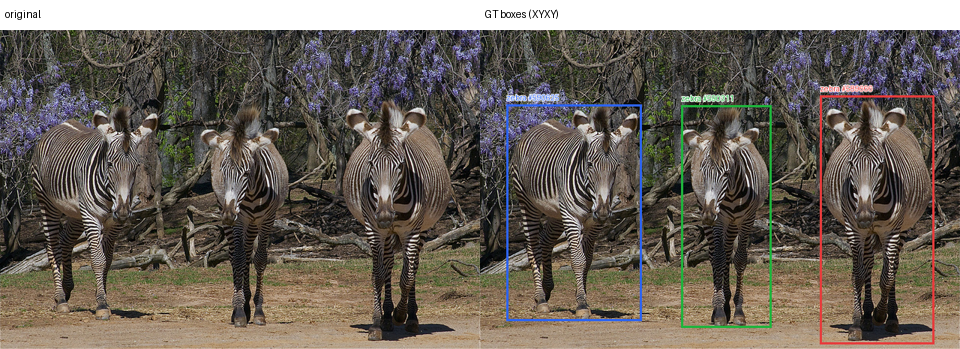

In [8]:
# 1-1 실습 코드
# 도움말 · len과 nunique가 세는 대상을 구분하세요.
cols = ["annotation_id", "category_id", "class_name", "xmin", "ymin", "xmax", "ymax"]
display(example_objects[cols])

n_images = example_objects["image_id"].nunique()     # 서로 다른 사진 수
n_objects = len(example_objects)                      # 행 수 = 객체(주석) 수
n_classes = example_objects["class_name"].nunique()   # 서로 다른 클래스 수
print("사진 수:", n_images, "/ 객체 수:", n_objects, "/ 클래스 수:", n_classes)
print("주석 번호:", example_objects["annotation_id"].tolist())
print("클래스 번호·이름:", example_objects[["category_id", "class_name"]].drop_duplicates().values.tolist())
show_panels([example_image, draw_boxes(example_image, example_objects)], ["original", "GT boxes (XYXY)"])


**나의 답안**

- **근거:** 11760번 사진의 주석은 3행입니다.
  - #589666: zebra, (453.65, 87.87, 605.51, 418.31)
  - #590311: zebra, (268.90, 100.52, 388.03, 396.24)
  - #590625: zebra, (35.26, 99.10, 215.36, 387.84)

  세 행의 클래스 번호는 모두 24(zebra)입니다. 세어 보면 **사진 수 1, 객체 수 3, 클래스 수 1**입니다.
- **판단:** 세 수는 세는 대상이 다릅니다.
  - `image_id.nunique()`는 서로 다른 사진 수를 셉니다.
  - `len(rows)`는 주석 행 수, 즉 개별 객체 수를 셉니다.
  - `class_name.nunique()`는 서로 다른 종류 수를 셉니다.

  얼룩말 세 마리는 같은 종류라서 클래스는 하나입니다. 하지만 각자 다른 주석 번호와 박스를 가진 별개의 객체입니다. 그래서 "무엇이 있나"(클래스)와 "몇 개가 어디 있나"(객체)는 다른 질문입니다.

### 1-2. XYXY와 XYWH를 왕복해 좌표 검증하기

세 박스의 너비와 높이를 계산해서 제공 열과 비교하세요. 첫 객체는 XYWH에서 XYXY로 복원하고 각 숫자의 위치·길이 의미를 설명하세요.

In [9]:
# 1-2 실습 코드
# 도움말 · 오른쪽 끝 좌표와 너비를 구분하세요.
check = example_objects[["annotation_id", "xmin", "ymin", "xmax", "ymax", "bbox_width", "bbox_height"]].copy()
check["계산 너비 (xmax-xmin)"] = (check.xmax - check.xmin).round(2)
check["계산 높이 (ymax-ymin)"] = (check.ymax - check.ymin).round(2)
check["너비 일치"] = np.isclose(check["계산 너비 (xmax-xmin)"], check.bbox_width, atol=0.01)
check["높이 일치"] = np.isclose(check["계산 높이 (ymax-ymin)"], check.bbox_height, atol=0.01)
display(check)

first = example_objects.iloc[0]
x, y, w, h = first.xmin, first.ymin, first.bbox_width, first.bbox_height
print(f"첫 객체 #{first.annotation_id} XYWH = ({x}, {y}, {w}, {h})")
print(f"  x={x}: 왼쪽 끝 위치 / y={y}: 위쪽 끝 위치 / w={w}: 가로 길이 / h={h}: 세로 길이")
restored = (x, y, round(x + w, 2), round(y + h, 2))
print(f"XYWH → XYXY 복원: ({x}, {y}, {x}+{w}, {y}+{h}) = {restored}")
print("제공 XYXY       :", (first.xmin, first.ymin, first.xmax, first.ymax))
print("복원 일치:", np.allclose(restored, [first.xmin, first.ymin, first.xmax, first.ymax], atol=0.01))


,annotation_id,xmin,ymin,xmax,ymax,bbox_width,bbox_height,계산 너비 (xmax-xmin),계산 높이 (ymax-ymin),너비 일치,높이 일치
796,589666,453.65,87.87,605.51,418.31,151.86,330.44,151.86,330.44,True,True
797,590311,268.90,100.52,388.03,396.24,119.13,295.72,119.13,295.72,True,True
798,590625,35.26,99.10,215.36,387.84,180.10,288.74,180.10,288.74,True,True


첫 객체 #589666 XYWH = (453.65, 87.87, 151.86, 330.44)
  x=453.65: 왼쪽 끝 위치 / y=87.87: 위쪽 끝 위치 / w=151.86: 가로 길이 / h=330.44: 세로 길이
XYWH → XYXY 복원: (453.65, 87.87, 453.65+151.86, 87.87+330.44) = (np.float64(453.65), np.float64(87.87), np.float64(605.51), np.float64(418.31))
제공 XYXY       : (np.float64(453.65), np.float64(87.87), np.float64(605.51), np.float64(418.31))
복원 일치: True


**나의 답안**

- **근거:** 세 박스 모두 `xmax − xmin`이 `bbox_width`(151.86, 119.13, 180.10)와 같고, `ymax − ymin`이 `bbox_height`(330.44, 295.72, 288.74)와 같습니다(전부 True).
  - 첫 객체 #589666의 XYWH는 (453.65, 87.87, 151.86, 330.44)입니다.
  - x = 453.65는 박스 **왼쪽 끝의 위치**, y = 87.87은 **위쪽 끝의 위치**입니다.
  - w = 151.86은 **가로 길이**, h = 330.44는 **세로 길이**입니다.
  - XYXY로 복원하면 (453.65, 87.87, 453.65 + 151.86, 87.87 + 330.44) = **(453.65, 87.87, 605.51, 418.31)**이고, 제공된 XYXY와 일치합니다.
- **판단:** XYXY의 뒤 두 숫자는 오른쪽·아래쪽 끝의 **위치**이고, XYWH의 뒤 두 숫자는 **길이**입니다. 둘 다 앞 두 숫자(왼쪽 위 꼭짓점)는 같습니다. 형식을 착각해 너비 151.86을 xmax로 쓰면 박스가 엉뚱한 곳에 그려집니다. 그래서 모델이나 도구가 어떤 형식을 쓰는지 먼저 확인해야 합니다.

### 1-3. 박스 안은 얼마나 이 얼룩말로 채워졌는가?

원본에 세 박스를 그리고 첫 얼룩말의 연속 좌표를 정수 픽셀 범위로 바꾸세요. 박스 안의 전체 픽셀 수·해당 객체의 픽셀 수·나머지 수와 점유율을 계산하세요.

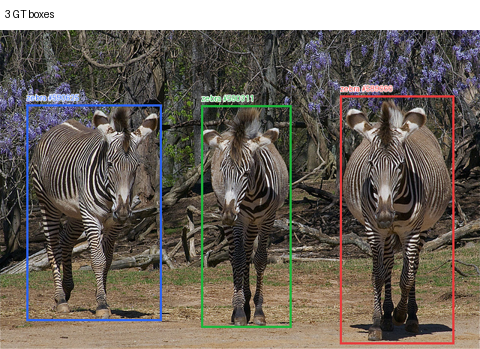

첫 얼룩말 #589666 연속 좌표: (453.65, 87.87, 605.51, 418.31)
정수 픽셀 범위: x 453~605 (열 153개), y 87~418 (행 332개)
박스 안 전체 픽셀: 153 × 332 = 50796
이 얼룩말 픽셀   : 30338
나머지 픽셀      : 20458
점유율           : 59.73%
마스크 전체 픽셀 : 30338 / 주석 area 열: 30324.8


,annotation_id,"정수 범위(x1,y1,x2,y2)",박스 픽셀,객체 픽셀,나머지,점유율(%)
0,589666,"(453, 87, 606, 419)",50796,30338,20458,59.73
1,590311,"(268, 100, 389, 397)",35937,20176,15761,56.14
2,590625,"(35, 99, 216, 388)",52309,27837,24472,53.22


In [10]:
# 1-3 실습 코드
# 도움말 · box_pixel_counts에 해당 객체의 이진 마스크와 해당 행을 같이 전달하세요.
show_panels([draw_boxes(example_image, example_objects)], ["3 GT boxes"])

first = example_objects.iloc[0]
first_mask = load_mask(first.mask_path) == 255          # 이 얼룩말만 True
(x1, y1, x2, y2), box_total, box_object = box_pixel_counts(first_mask, first)
rest = box_total - box_object
print(f"첫 얼룩말 #{first.annotation_id} 연속 좌표: ({first.xmin}, {first.ymin}, {first.xmax}, {first.ymax})")
print(f"정수 픽셀 범위: x {x1}~{x2 - 1} (열 {x2 - x1}개), y {y1}~{y2 - 1} (행 {y2 - y1}개)")
print(f"박스 안 전체 픽셀: {x2 - x1} × {y2 - y1} = {box_total}")
print("이 얼룩말 픽셀   :", box_object)
print("나머지 픽셀      :", rest)
print(f"점유율           : {box_object / box_total:.2%}")
print("마스크 전체 픽셀 :", int(first_mask.sum()), "/ 주석 area 열:", round(first.area, 1))

table = []
for _, row in example_objects.iterrows():
    m = load_mask(row.mask_path) == 255
    rng, total, obj = box_pixel_counts(m, row)
    table.append({"annotation_id": row.annotation_id, "정수 범위(x1,y1,x2,y2)": rng, "박스 픽셀": total,
                  "객체 픽셀": obj, "나머지": total - obj, "점유율(%)": round(100 * obj / total, 2)})
display(pd.DataFrame(table))


**나의 답안**

- **근거:** 첫 얼룩말 #589666의 연속 좌표 (453.65, 87.87, 605.51, 418.31)를 정수 픽셀 범위로 바꿨습니다. 시작은 내림, 끝은 올림입니다.
  - 정수 범위: x 453~605(열 153개), y 87~418(행 332개)
  - 박스 안 전체 픽셀: 153 × 332 = **50,796**
  - 이 얼룩말 픽셀: **30,338**
  - 나머지 픽셀: **20,458**
  - 점유율: **59.73%**

  나머지 두 마리의 점유율은 56.14%와 53.22%입니다. 마스크 전체 픽셀 30,338은 주석의 `area` 열(30,324.8, 다각형 면적)과 거의 같습니다.
- **판단:** 박스는 객체를 감싸는 가장 작은 직사각형일 뿐입니다. 그래서 박스 안의 약 40%는 배경(풀밭)이거나 다른 얼룩말의 일부입니다. 박스만으로는 "어느 픽셀이 이 얼룩말인가"를 알 수 없고, 면적이나 윤곽이 필요하면 마스크가 필요합니다.

### 1-4. 라벨을 어떻게 만들어야 질문에 답할 수 있을까?

① 얼룩말이 있는지 ② 각 얼룩말의 위치와 마릿수 ③ 개체별 몸의 윤곽을 알기 위해 필요한 출력·모델 예·학습 라벨을 정리하세요. 한 종류의 출력으로 다른 질문까지 답할 수 있는지도 설명하세요.

**나의 답안**

| 질문 | 필요한 출력 | 모델 예 | 학습 라벨 |
|---|---|---|---|
| ① 얼룩말이 있는가 | 사진 한 장당 클래스 점수(있음/없음) | 이미지 분류 (ResNet 등, 다중 라벨) | 사진 단위 클래스 라벨 |
| ② 각 얼룩말의 위치와 마릿수 | 객체마다 박스 + 클래스 + 점수 | 객체 탐지 (Faster R-CNN, YOLO, DETR) | 객체별 박스(XYXY/XYWH) + 클래스 |
| ③ 개체별 몸의 윤곽 | 객체마다 픽셀 마스크 + 박스 + 클래스 | 인스턴스 세그멘테이션 (Mask R-CNN) | 객체별 이진 마스크 (+ 박스, 클래스) |

- **근거:** 11760번 사진에서 분류 라벨은 "zebra" 하나입니다. 탐지 라벨은 박스 3개이고, 인스턴스 마스크는 30,338, 20,176, 27,837픽셀짜리 3장입니다.
- **판단:** 정보는 위에서 아래로만 내려갈 수 있습니다.
  - 인스턴스 마스크가 있으면 박스(마스크의 최소·최대 좌표), 마릿수(마스크 수), 존재 여부를 모두 구할 수 있습니다.
  - 박스로는 존재 여부와 마릿수는 알 수 있지만 윤곽은 알 수 없습니다. 박스 안의 약 40%가 배경이기 때문입니다.
  - 분류 결과 하나로는 위치도 마릿수도 알 수 없습니다.

  따라서 질문이 요구하는 가장 자세한 수준에 맞춰 라벨과 모델을 정해야 합니다. 대신 자세한 라벨일수록 만드는 비용이 커집니다.

## 필수 2 · 정답 마스크와 실제 모델의 신뢰도 해석하기

### 2-1. 한 점의 좌표로 마스크의 행·열 순서 확인하기

첫 주석의 마스크 크기·고유값을 출력하세요. 사진의 (x=590, y=221)과 (0, 0)에서 해당 객체의 포함 여부를 읽고 원본·박스·마스크 그림과 연결하세요.

마스크 shape (행=높이, 열=너비): (425, 640) / 사진 크기 (너비, 높이): (640, 425)
고유값: [0, 255] / dtype: uint8
(x=590, y=221) → mask[221, 590] = 255 → 이 얼룩말 포함
(x=0, y=0) → mask[0, 0] = 0 → 이 얼룩말 미포함
참고: 순서를 바꾼 mask[590, 221]은 행이 425개뿐이라 IndexError가 납니다.


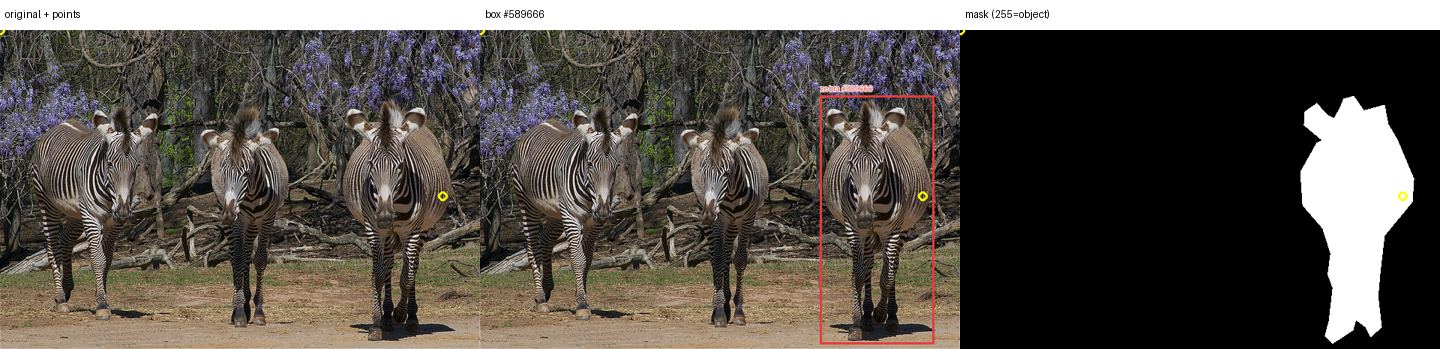

In [11]:
# 2-1 실습 코드
# 도움말 · 배열 인덱스는 [y, x]입니다.
first = example_objects.iloc[0]
mask_raw = load_mask(first.mask_path)
print("마스크 shape (행=높이, 열=너비):", mask_raw.shape, "/ 사진 크기 (너비, 높이):", example_image.size)
print("고유값:", np.unique(mask_raw).tolist(), "/ dtype:", mask_raw.dtype)

for (px, py) in [(590, 221), (0, 0)]:
    v = mask_raw[py, px]                     # [y, x] 순서
    print(f"(x={px}, y={py}) → mask[{py}, {px}] = {v} → 이 얼룩말 {'포함' if v == 255 else '미포함'}")
print("참고: 순서를 바꾼 mask[590, 221]은 행이 425개뿐이라 IndexError가 납니다.")

def mark(img, pts):
    view = img.copy(); d = ImageDraw.Draw(view)
    for px, py in pts:
        d.ellipse((px - 6, py - 6, px + 6, py + 6), outline=(255, 255, 0), width=3)
    return view
pts = [(590, 221), (0, 0)]
mask_view = Image.fromarray(mask_raw).convert("RGB")
show_panels([mark(example_image, pts),
             mark(draw_boxes(example_image, example_objects.iloc[[0]]), pts),
             mark(mask_view, pts)],
            ["original + points", f"box #{first.annotation_id}", "mask (255=object)"])


**나의 답안**

- **근거:** 첫 주석 #589666의 마스크는 shape **(425, 640)**, uint8이고, 고유값은 **[0, 255]**입니다(255 = 이 얼룩말, 0 = 나머지). 사진 크기 `size`는 (640, 425) = (너비, 높이)인데 배열은 (행 = 높이, 열 = 너비) 순서입니다.
  - 사진의 (x=590, y=221)은 `mask[221, 590]` = **255**로, 이 얼룩말에 **포함**됩니다. 그림에서도 오른쪽 얼룩말 몸통 위 점입니다.
  - (0, 0)은 `mask[0, 0]` = **0**으로, **미포함**입니다. 왼쪽 위 모서리 배경입니다.
- **판단:** 좌표는 (x, y)로 말하지만 배열은 **[y, x]**로 접근해야 합니다. 순서를 바꿔 `mask[590, 221]`로 쓰면 행이 425개뿐이라 IndexError가 나고, 크기가 맞는 사진이라면 오류 없이 엉뚱한 점을 읽게 됩니다. 원본, 박스, 마스크 세 그림에서 같은 점을 표시해 위치가 일치하는 것을 확인했습니다.

### 2-2. 객체별 마스크 세 장을 합치면 무엇이 사라질까?

세 마스크를 서로 다른 색으로 표시하세요. 각 객체의 픽셀 수·세 마스크의 합집합 면적·둘 이상 겹친 픽셀 수를 구하고, 클래스별 마스크 한 장으로 합칠 때 잃는 정보를 설명하세요.

마스크 묶음 shape (객체, 높이, 너비): (3, 425, 640)


,annotation_id,객체 픽셀 수
0,589666,30338
1,590311,20176
2,590625,27837


객체별 픽셀 합계        : 78351
합집합(클래스 마스크) 면적: 78351
둘 이상 겹친 픽셀 수     : 0
합계 - 합집합            : 0


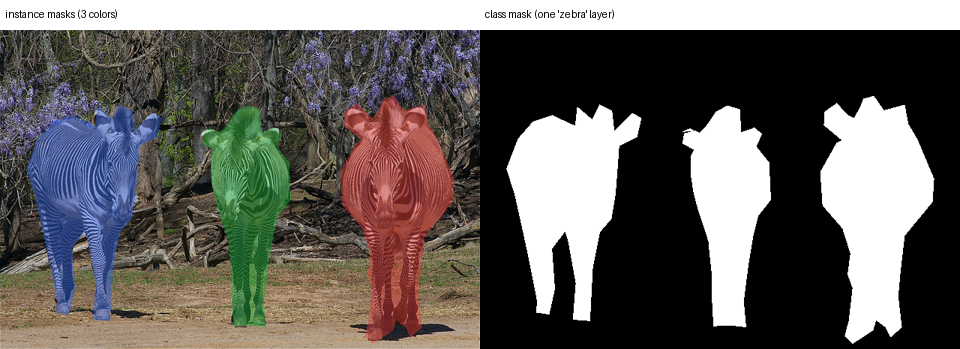

In [12]:
# 2-2 실습 코드
# 도움말 · 객체 축(axis=0)을 따라 any와 sum을 적용해 보세요.
masks = np.stack([load_mask(p) == 255 for p in example_objects.mask_path])   # (객체 수, H, W)
print("마스크 묶음 shape (객체, 높이, 너비):", masks.shape)

per_object = masks.sum(axis=(1, 2))
union_mask = masks.any(axis=0)            # 클래스 마스크: 어느 얼룩말이든 True
count_map = masks.sum(axis=0)             # 픽셀마다 몇 개 객체가 덮는지
overlap = int((count_map >= 2).sum())

display(pd.DataFrame({"annotation_id": example_objects.annotation_id.values, "객체 픽셀 수": per_object}))
print("객체별 픽셀 합계        :", int(per_object.sum()))
print("합집합(클래스 마스크) 면적:", int(union_mask.sum()))
print("둘 이상 겹친 픽셀 수     :", overlap)
print("합계 - 합집합            :", int(per_object.sum() - union_mask.sum()))

class_mask_view = Image.fromarray((union_mask * 255).astype(np.uint8)).convert("RGB")
show_panels([draw_masks(example_image, example_objects), class_mask_view],
            ["instance masks (3 colors)", "class mask (one 'zebra' layer)"])


**나의 답안**

- **근거:** 세 마스크를 쌓은 배열은 (3, 425, 640)입니다.
  - 객체별 픽셀 수: 30,338, 20,176, 27,837 → 합계 **78,351**
  - `any(axis=0)`로 구한 합집합(클래스 마스크) 면적: **78,351**
  - `sum(axis=0) >= 2`로 구한, 둘 이상 겹친 픽셀: **0**

  이 사진에서는 세 마리의 주석이 서로 겹치지 않아 합계와 합집합이 같습니다.
- **판단:** 겹친 픽셀이 0이어도 클래스 마스크 한 장으로 합치면 **"어느 픽셀이 몇 번째 얼룩말인가"라는 개체 구분**이 사라집니다.
  - 합친 마스크로는 마릿수를 바로 셀 수 없습니다. 붙어 있는 두 마리는 하나의 덩어리로 보입니다.
  - 개체별 면적(30,338 등)과 개체별 박스도 복원할 수 없습니다.
  - 겹침이 있는 사진이라면 겹친 픽셀이 누구 것인지 정보도 사라지고, 합집합은 객체별 합계보다 작아집니다.

  그래서 시맨틱 세그멘테이션(클래스 마스크)은 "얼룩말 영역"에, 인스턴스 세그멘테이션은 "각 얼룩말"에 답합니다.

### 2-3. 실제 예측에서 점수 기준을 높이면 어느 정답이 빠지는가?

사전학습 Mask R-CNN으로 8장을 추론하고 0.50·0.70에서 TP·FP·FN, Precision·Recall을 비교하세요. 평가 사진 210099의 고양이 예측이 각 기준에서 어떻게 처리됐는지 표와 원본으로 설명하세요.

평가 사진: [11760, 22892, 68933, 17115, 176857, 210099, 171611, 143961]


,TP,FP,FN,precision,recall,matched_mask_iou
cutoff,,,,,,
0.5,11,0,4,1.0,0.733,0.863
0.7,10,0,5,1.0,0.667,0.890


정답 수      TP      FP      FN    
cutoff    0.5 0.7 0.5 0.7 0.5 0.7 0.5 0.7
image_id                                 
11760       3   3   3   3   0   0   0   0
17115       2   2   2   2   0   0   0   0
22892       2   2   2   2   0   0   0   0
68933       3   3   3   3   0   0   0   0
143961      2   2   0   0   0   0   2   2
171611      1   1   0   0   0   0   1   1
176857      1   1   0   0   0   0   1   1
210099      1   1   1   0   0   0   0   1


210099 정답 (관심 클래스):


,annotation_id,class_name,xmin,ymin,xmax,ymax
13482,51207,cat,155.04,81.79,384.12,448.56


모델 예측 (관심 클래스, 점수순):


,rank,class_name,score,box
0,2,cat,0.6316,"[141.0, 91.0, 314.3, 407.7]"
1,3,cat,0.4685,"[147.4, 87.5, 446.9, 457.5]"



[기준 0.5] 매칭 표 / 놓친 정답 ID: []


,rank,name,score,matched_id,box_iou,mask_iou
0,2,cat,0.6316,51207,0.5703,0.5955



[기준 0.7] 매칭 표 / 놓친 정답 ID: [51207]


,rank,name,score,matched_id,box_iou,mask_iou


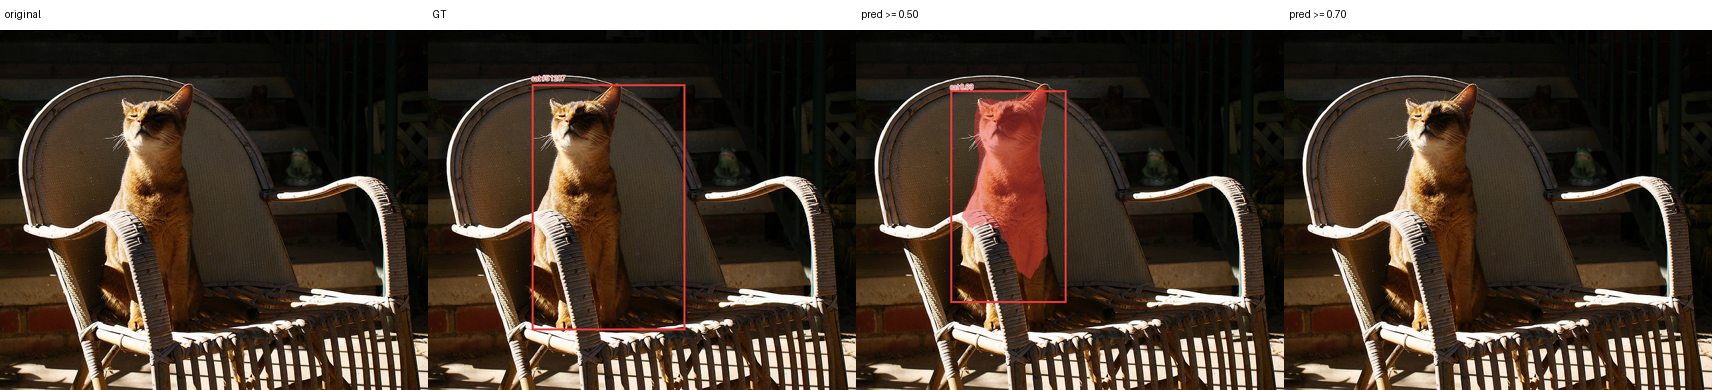

In [13]:
# 2-3 실습 코드
# 도움말 · make_model, score_set, draw_predictions를 사용할 수 있습니다. 박스 IoU ≥ 0.50인 같은 클래스끼리만 일대일로 연결합니다.
eval_model = make_model()
summary, details = score_set(eval_model, eval_ids, SCORES)
print("평가 사진:", eval_ids)
display(summary.round(3))

per_image = []
for (image_id, cutoff), t in details.items():
    tp = int(t.matched_id.notna().sum())
    _, gt_rows = get_example(image_id)
    n_gt = int(gt_rows.class_name.isin(TARGETS).sum())
    per_image.append({"image_id": image_id, "cutoff": cutoff, "정답 수": n_gt, "TP": tp, "FP": len(t) - tp, "FN": n_gt - tp})
display(pd.DataFrame(per_image).pivot(index="image_id", columns="cutoff", values=["정답 수", "TP", "FP", "FN"]))

CHECK_ID = 210099
img_c, rows_c = get_example(CHECK_ID)
print(f"\n{CHECK_ID} 정답 (관심 클래스):")
display(rows_c.loc[rows_c.class_name.isin(TARGETS), ["annotation_id", "class_name", "xmin", "ymin", "xmax", "ymax"]])
preds_c = predict(eval_model, img_c)
print("모델 예측 (관심 클래스, 점수순):")
display(pd.DataFrame([{k: (round(v, 4) if k == "score" else v) for k, v in p.items() if k in ("rank", "class_name", "score")}
                      | {"box": [round(b, 1) for b in p["box"].tolist()]} for p in preds_c]))
for cutoff in SCORES:
    t, missed = match_one_image(rows_c, preds_c, cutoff)
    print(f"\n[기준 {cutoff}] 매칭 표 / 놓친 정답 ID: {missed}")
    display(t.round(4))
show_panels([img_c, draw_boxes(img_c, rows_c[rows_c.class_name.isin(TARGETS)]),
             draw_predictions(img_c, preds_c, 0.50), draw_predictions(img_c, preds_c, 0.70)],
            ["original", "GT", "pred >= 0.50", "pred >= 0.70"])


**나의 답안**

- **근거:** 사전학습 Mask R-CNN으로 평가 사진 8장(정답 객체 15개)을 추론했습니다.

| 기준 | TP | FP | FN | Precision | Recall | 매칭 마스크 IoU 평균 |
|---|---:|---:|---:|---:|---:|---:|
| 0.50 | 11 | 0 | 4 | 1.000 | 0.733 | 0.863 |
| 0.70 | 10 | 0 | 5 | 1.000 | 0.667 | 0.890 |

  - **210099의 정답과 예측:** 정답은 고양이 #51207 한 마리입니다. 관심 클래스 예측은 rank 2 cat(점수 0.6316)과 rank 3 cat(0.4685) 두 개입니다.
  - **기준 0.50:** rank 3(0.4685)은 기준 미만이라 처음부터 제외됩니다. rank 2(0.6316)가 박스 IoU **0.5703**(≥ 0.50)으로 #51207과 연결되어 **TP**가 됩니다. 마스크 IoU는 0.5955입니다.
  - **기준 0.70:** 0.6316 예측도 제외되어 연결할 예측이 없습니다. 정답 #51207이 **FN**(놓친 정답)이 됩니다.
  - **나머지 FN 4개:** 143961(2개), 171611(1개), 176857(1개)에서는 관심 클래스 예측이 0.50 이상으로 하나도 나오지 않아 두 기준 모두 FN입니다.
- **판단:** 기준을 0.50에서 0.70으로 올렸을 때 **바뀐 것은 210099의 고양이 하나뿐**입니다. TP가 11에서 10으로 줄고 FN이 4에서 5로 늘어, Recall이 0.733에서 0.667로 떨어졌습니다. FP는 원래 0이라 Precision은 1.0 그대로이므로, 이 표본에서는 기준을 높여도 얻은 것 없이 정답 하나만 잃었습니다.

### 2-4. 어떤 기준이 이 표본의 목적에 맞는가?

“놓치는 동물을 줄이자”가 목적일 때 두 기준 중 하나를 고르세요. Confidence, 검출의 정오, 매칭된 마스크의 평균 IoU가 각각 무엇을 재는지 설명하고 분모가 달라지는 사례를 인용하세요.

**나의 답안**

- **근거:** 목적이 "놓치는 동물을 줄이자"라면 Recall이 중요합니다. 0.50의 Recall은 0.733(11/15)이고 0.70은 0.667(10/15)입니다. 두 기준 모두 FP는 0입니다.
- **판단: 기준 0.50을 선택합니다.** 0.70은 210099의 고양이(점수 0.6316, 실제로 맞는 검출)를 버려 FN을 하나 늘렸고, 대신 줄인 FP도 없습니다.

세 지표가 재는 것은 서로 다릅니다.

| 지표 | 무엇을 재나 | 210099 고양이 예시 |
|---|---|---|
| **Confidence(점수)** | 모델이 스스로 매긴 확신. 정답을 보지 않고 계산 | 0.6316 |
| **검출의 정오(TP/FP/FN)** | 같은 클래스이고 박스 IoU ≥ 0.50인 정답과 일대일로 연결됐는지 | 0.50에서는 TP(박스 IoU 0.5703), 0.70에서는 FN |
| **매칭된 마스크의 평균 IoU** | **TP가 된 것만** 대상으로, 윤곽이 픽셀 단위로 얼마나 맞는지 | 0.5955 |

**분모가 달라지는 사례:** 매칭 마스크 IoU 평균은 0.50에서 0.863이었는데 0.70에서는 0.890으로 **올랐습니다**.
- 마스크 품질이 좋아진 것이 아닙니다. IoU가 가장 낮던 210099 고양이(0.5955)가 TP에서 빠졌기 때문입니다.
- 분모가 11에서 10으로 줄었습니다. 검산하면 (0.863 × 11 − 0.5955) / 10 ≈ 0.890입니다.
- 마찬가지로 Precision의 분모(TP + FP)와 Recall의 분모(정답 15개)도 서로 다릅니다.

따라서 평균 IoU가 올랐다는 것만 보고 "더 좋아졌다"고 판단하면 안 되고, 몇 개를 평균했는지 함께 봐야 합니다.

## 과제 1 · 다른 장면에 적용하고 실제 마스크 층 학습 전후 검증하기

### 3-1. 사진 속 다섯 정답과 평가 대상 구분하기

22892번 사진에서 모든 개별 객체의 클래스·박스·너비·높이를 표로 만드세요. 전체 객체와 세 관심 클래스에 속하는 객체 수를 구한 뒤 고양이 한 마리의 XYWH와 박스 안 마스크 점유율을 구하세요.

,annotation_id,class_name,xmin,ymin,xmax,ymax,bbox_width,bbox_height,관심 클래스
1553,3944,dog,35.62,76.00,288.97,295.76,253.35,219.76,True
1554,22287,potted plant,202.36,218.15,451.35,330.99,248.99,112.84,False
1555,46699,cat,237.75,23.48,499.20,254.05,261.45,230.57,True
1556,118600,dining table,347.30,229.26,500.00,330.16,152.70,100.90,False
1557,1930326,chair,314.10,0.00,500.00,259.59,185.90,259.59,False


사진 크기: (500, 334)
전체 개별 객체 수: 5 / 관심 클래스(zebra·cat·dog) 객체 수: 2
클래스별: {'dog': 1, 'potted plant': 1, 'cat': 1, 'dining table': 1, 'chair': 1}


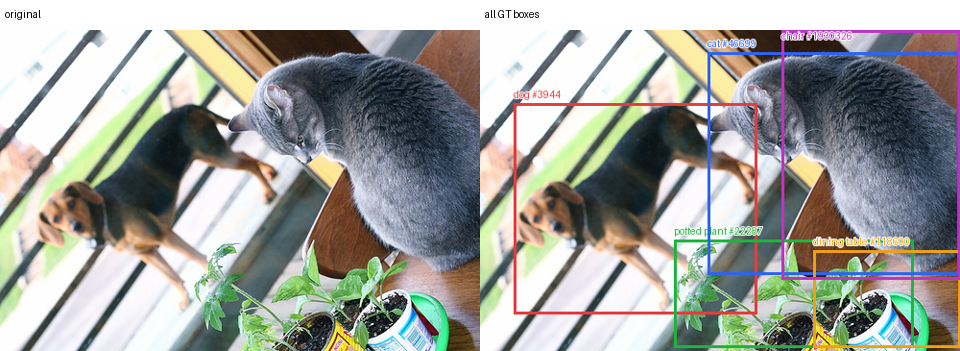


고양이 #46699 XYWH = (237.75, 23.48, 261.45, 230.57)
정수 범위 (np.int64(237), np.int64(23), np.int64(500), np.int64(255)) → 박스 픽셀 61016, 고양이 픽셀 35117, 나머지 25899, 점유율 57.55%


In [14]:
# 3-1 실습 코드
# 도움말 · get_example(TASK_ID)로 새로 시작하세요. 모델의 출력과 비교할 때 사용할 정답 범위를 먼저 정합니다.
task_image, task_rows = get_example(TASK_ID)
task_table = task_rows[["annotation_id", "class_name", "xmin", "ymin", "xmax", "ymax", "bbox_width", "bbox_height"]].copy()
task_table["관심 클래스"] = task_table.class_name.isin(TARGETS)
display(task_table)
print("사진 크기:", task_image.size)
print("전체 개별 객체 수:", len(task_rows), "/ 관심 클래스(zebra·cat·dog) 객체 수:", int(task_table["관심 클래스"].sum()))
print("클래스별:", task_rows.class_name.value_counts().to_dict())
show_panels([task_image, draw_boxes(task_image, task_rows)], ["original", "all GT boxes"])

cat_row = task_rows[task_rows.class_name == "cat"].iloc[0]
print(f"\n고양이 #{cat_row.annotation_id} XYWH = ({cat_row.xmin}, {cat_row.ymin}, {cat_row.bbox_width}, {cat_row.bbox_height})")
cat_mask = load_mask(cat_row.mask_path) == 255
rng, total, obj = box_pixel_counts(cat_mask, cat_row)
print(f"정수 범위 {rng} → 박스 픽셀 {total}, 고양이 픽셀 {obj}, 나머지 {total - obj}, 점유율 {obj / total:.2%}")


**나의 답안**

- **근거:** 22892번 사진(500×334)의 개별 객체는 **5개**입니다.

| 주석 | 클래스 | 박스 (XYXY) | 너비 × 높이 |
|---|---|---|---|
| #3944 | dog | (35.62, 76.00, 288.97, 295.76) | 253.35 × 219.76 |
| #22287 | potted plant | (202.36, 218.15, 451.35, 330.99) | 248.99 × 112.84 |
| #46699 | cat | (237.75, 23.48, 499.20, 254.05) | 261.45 × 230.57 |
| #118600 | dining table | (347.30, 229.26, 500.00, 330.16) | 152.70 × 100.90 |
| #1930326 | chair | (314.10, 0.00, 500.00, 259.59) | 185.90 × 259.59 |

  - 이 중 관심 클래스(zebra·cat·dog)는 **2개**(dog #3944, cat #46699)입니다.
  - 고양이 #46699의 XYWH는 **(237.75, 23.48, 261.45, 230.57)**입니다.
  - 정수 범위 (237, 23, 500, 255)에서 박스 픽셀 **61,016**, 고양이 픽셀 **35,117**, 나머지 25,899이고, 점유율은 **57.55%**입니다.
- **판단:** 평가 대상은 5개가 아니라 관심 클래스 2개입니다. 화분, 식탁, 의자 예측은 `predict`에서 걸러지므로 FP나 FN으로 세지 않습니다. 고양이 박스도 약 42%가 배경과 의자 등이라, 윤곽 비교에는 마스크가 필요합니다.

### 3-2. 고양이의 정답·예측 마스크를 픽셀 단위로 대조하기

새 사전학습 모델을 준비하세요. 22892에서 점수 0.50을 적용하고 고양이 정답과 연결된 예측을 찾으세요. 원본·정답·예측·오차 그림을 표시하고, 교집합과 합집합을 세어 마스크 IoU를 검산하세요.

기준 0.50 매칭 표 / 놓친 정답: []


,rank,name,score,matched_id,box_iou,mask_iou
0,1,cat,0.8836,46699,0.9451,0.9413
1,2,dog,0.8417,3944,0.8676,0.8448


예측 rank 1 (점수 0.8836) ↔ 정답 고양이 #46699 / 박스 IoU 0.9451
정답 픽셀 35117, 예측 픽셀 35261
교집합 34125, 합집합 36253 → 마스크 IoU = 34125/36253 = 0.9413
표의 mask_iou = 0.9413 / 일치: True
놓친 픽셀(정답만) 992, 넘친 픽셀(예측만) 1136, 검산: 34125+992+1136 = 36253 (= 합집합)


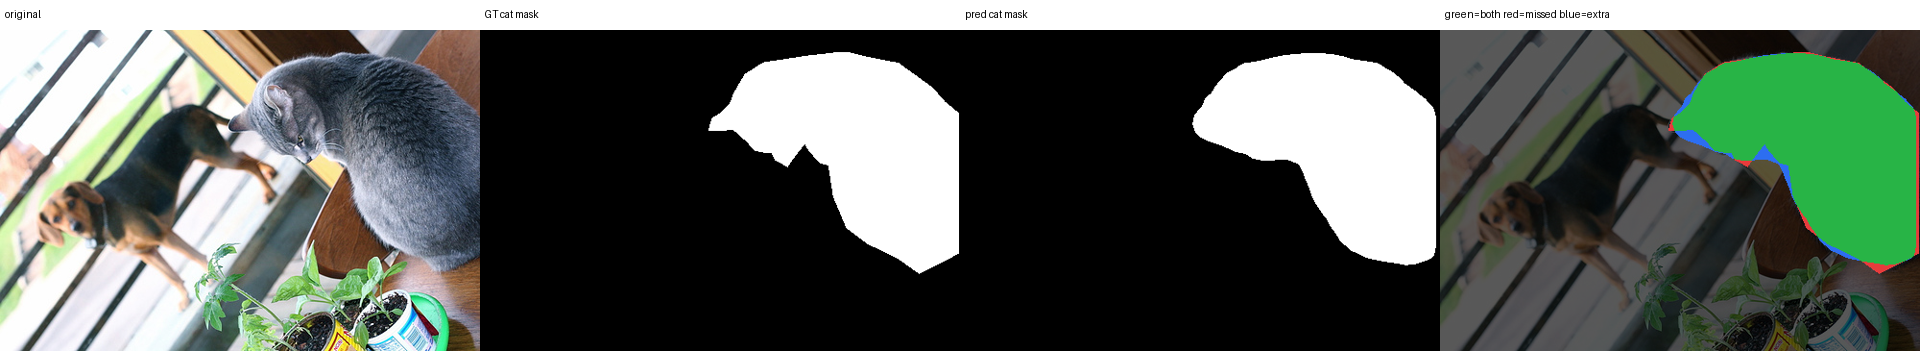

In [15]:
# 3-2 실습 코드
# 도움말 · match_one_image가 돌려준 matched_id로 개체를 찾으세요. 같은 클래스라도 첫 후보가 항상 같은 개체라는 보장은 없습니다.
task_model = make_model()        # 새 사전학습 모델
task_preds = predict(task_model, task_image)
match_table, missed = match_one_image(task_rows, task_preds, 0.50)
print("기준 0.50 매칭 표 / 놓친 정답:", missed)
display(match_table.round(4))

cat_hits = match_table[(match_table.name == "cat") & match_table.matched_id.notna()]
if cat_hits.empty:
    print("고양이 정답과 연결된 예측이 없습니다.")
else:
    hit = cat_hits.iloc[0]
    pred = next(p for p in task_preds if p["rank"] == hit["rank"])
    gt_row = task_rows.set_index("annotation_id").loc[int(hit.matched_id)]
    gt_mask = load_mask(gt_row.mask_path) == 255
    pr_mask = pred["mask"]
    inter = int(np.count_nonzero(gt_mask & pr_mask))
    union = int(np.count_nonzero(gt_mask | pr_mask))
    fn = int(np.count_nonzero(gt_mask & ~pr_mask))
    fp = int(np.count_nonzero(~gt_mask & pr_mask))
    print(f"예측 rank {int(hit['rank'])} (점수 {hit.score:.4f}) ↔ 정답 고양이 #{int(hit.matched_id)} / 박스 IoU {hit.box_iou:.4f}")
    print(f"정답 픽셀 {int(gt_mask.sum())}, 예측 픽셀 {int(pr_mask.sum())}")
    print(f"교집합 {inter}, 합집합 {union} → 마스크 IoU = {inter}/{union} = {inter / union:.4f}")
    print(f"표의 mask_iou = {hit.mask_iou:.4f} / 일치: {np.isclose(inter / union, hit.mask_iou)}")
    print(f"놓친 픽셀(정답만) {fn}, 넘친 픽셀(예측만) {fp}, 검산: {inter}+{fn}+{fp} = {inter + fn + fp} (= 합집합)")

    base = np.asarray(task_image).astype(float)
    err = base * 0.35
    err[gt_mask & pr_mask] = [40, 180, 70]      # 둘 다: 초록
    err[gt_mask & ~pr_mask] = [230, 60, 60]     # 정답만(놓침): 빨강
    err[~gt_mask & pr_mask] = [45, 110, 240]    # 예측만(넘침): 파랑
    gt_view = Image.fromarray((gt_mask * 255).astype(np.uint8)).convert("RGB")
    pr_view = Image.fromarray((pr_mask * 255).astype(np.uint8)).convert("RGB")
    show_panels([task_image, gt_view, pr_view, Image.fromarray(err.astype(np.uint8))],
                ["original", "GT cat mask", "pred cat mask", "green=both red=missed blue=extra"])


**나의 답안**

- **근거:** 새 사전학습 모델로 22892를 추론하고 점수 0.50을 적용했습니다. 매칭 결과는 다음과 같습니다.
  - rank 1 cat(점수 **0.8836**) ↔ 정답 고양이 **#46699**: 박스 IoU 0.9451, 마스크 IoU 0.9413
  - rank 2 dog(0.8417) ↔ #3944: 박스 IoU 0.8676, 마스크 IoU 0.8448
  - 놓친 정답은 없습니다.

  `matched_id`로 고양이 정답을 찾아 픽셀을 직접 셌습니다.
  - 정답 마스크 35,117픽셀, 예측 마스크 35,261픽셀
  - **교집합 34,125**, **합집합 36,253**
  - 마스크 IoU = 34,125 / 36,253 = **0.9413**으로, 표의 `mask_iou`와 일치합니다.
  - 오차 그림 색: 놓친 픽셀(정답에만 있음, 빨강) 992, 넘친 픽셀(예측에만 있음, 파랑) 1,136
  - 검산: 34,125 + 992 + 1,136 = 36,253 = 합집합
- **판단:** 사전학습 모델이 이 고양이의 위치(박스 IoU 0.945)와 윤곽(마스크 IoU 0.941)을 모두 잘 잡았습니다. 오차는 빨강과 파랑이 경계를 따라 얇게 나타나는 형태입니다. 즉 몸통 전체를 놓친 것이 아니라 **경계 픽셀**에서 생겼습니다. 정답 마스크는 사람이 찍은 각진 다각형이고 예측은 둥근 윤곽이라, 귀 끝, 머리 아래, 오른쪽 사진 가장자리처럼 모양이 꺾이는 곳에서 차이가 납니다. 고양이 정답을 찾을 때 "첫 cat 예측"이 아니라 `matched_id`로 연결된 예측을 사용했습니다.

### 3-3. 12장으로 마스크 층을 학습하고 같은 평가 사진에 다시 적용하기

독립 과제의 모델을 새 사전학습 가중치로 시작하세요. 미세조정 전 8장 평가, 서로 다른 12장으로 마스크 출력층 1에포크 학습, 같은 8장 재평가를 수행하세요. 학습 객체 수·가중치 변화·손실을 기록하고 검출 결과와 매칭된 마스크 IoU를 전후 비교하세요.

In [16]:
# 3-3 실습 코드
# 도움말 · score_set → tune_mask → score_set 순서입니다. 같은 기준 0.50의 같은 열을 비교하세요.
tuned_model = make_model()       # 새 사전학습 가중치로 시작
assert set(train_ids).isdisjoint(eval_ids)

before, before_details = score_set(tuned_model, eval_ids, [0.50])
history, weight_change = tune_mask(tuned_model, train_ids)
after, after_details = score_set(tuned_model, eval_ids, [0.50])

print("학습 기록 (사진당 1회 갱신, 1에포크):")
display(history.round(4))
print("학습 객체 수 합계:", int(history.objects.sum()), "/ 마지막 마스크 층 가중치 최대 변화:", weight_change)

compare = pd.concat({"before": before, "after": after}).round(4)
display(compare)

rows_cmp = []
for image_id in eval_ids:
    b = before_details[image_id, 0.50]; a = after_details[image_id, 0.50]
    rows_cmp.append({"image_id": image_id, "TP 전": int(b.matched_id.notna().sum()), "TP 후": int(a.matched_id.notna().sum()),
                     "mask IoU 전": round(b.mask_iou.mean(), 4), "mask IoU 후": round(a.mask_iou.mean(), 4)})
display(pd.DataFrame(rows_cmp))

for label, d in [("전", before_details), ("후", after_details)]:
    t = d[TASK_ID, 0.50]
    print(f"{TASK_ID} 고양이 ({label}):", t[t.name == "cat"][["rank", "score", "matched_id", "box_iou", "mask_iou"]].round(4).to_dict("records"))


학습 기록 (사진당 1회 갱신, 1에포크):


,image_id,objects,loss_mask
0,110211,5,0.4384
1,124975,2,0.4440
2,69106,4,0.3616
3,172977,1,0.1526
4,169076,2,0.2144
5,118515,1,0.1265
6,219578,2,0.1559
7,166277,1,0.1588
8,189806,2,0.1731
9,88951,1,0.2399


학습 객체 수 합계: 23 / 마지막 마스크 층 가중치 최대 변화: 0.001401647925376892


,,TP,FP,FN,precision,recall,matched_mask_iou
,cutoff,,,,,,
before,0.5,11,0,4,1.0,0.7333,0.8631
after,0.5,11,0,4,1.0,0.7333,0.8631


,image_id,TP 전,TP 후,mask IoU 전,mask IoU 후
0,11760,3,3,0.8836,0.8835
1,22892,2,2,0.8930,0.8926
2,68933,3,3,0.9082,0.9083
3,17115,2,2,0.8688,0.8688
4,176857,0,0,NaN,NaN
5,210099,1,1,0.5955,0.5955
6,171611,0,0,NaN,NaN
7,143961,0,0,NaN,NaN


22892 고양이 (전): [{'rank': 1, 'score': 0.8836, 'matched_id': 46699, 'box_iou': 0.9451, 'mask_iou': 0.9413}]
22892 고양이 (후): [{'rank': 1, 'score': 0.8836, 'matched_id': 46699, 'box_iou': 0.9451, 'mask_iou': 0.9414}]


**나의 답안**

- **근거:** 새 사전학습 모델로 시작해 학습 사진 12장(평가 8장과 ID가 겹치지 않음)으로 마스크 출력층 `mask_fcn_logits`만 1에포크 학습했습니다. 사진당 1회씩, 총 12번 갱신했습니다.
  - 학습 객체 수: **23개**
  - `loss_mask`: 사진마다 0.1265~0.7947
  - 가중치 최대 변화: **0.0014**

| 기준 0.50 | TP | FP | FN | Precision | Recall | 매칭 마스크 IoU |
|---|---:|---:|---:|---:|---:|---:|
| 학습 전 | 11 | 0 | 4 | 1.0 | 0.7333 | 0.8631 |
| 학습 후 | 11 | 0 | 4 | 1.0 | 0.7333 | 0.8631 |

  사진별 마스크 IoU는 소수 넷째 자리에서만 바뀌었습니다.
  - 11760: 0.8836 → 0.8835
  - 22892: 0.8930 → 0.8926
  - 68933: 0.9082 → 0.9083
  - 22892 고양이: 0.9413 → 0.9414
- **판단:** 학습은 실제로 일어났습니다(가중치 변화 0.0014). 하지만 **검출 결과는 전혀 바뀌지 않았고, 마스크 IoU 변화도 ±0.0004 이내로 의미가 없습니다.**
  - 검출이 그대로인 것은 당연합니다. 박스와 점수를 만드는 층은 고정하고 마스크 층만 갱신했기 때문입니다.
  - 마스크가 거의 그대로인 이유는 학습량이 너무 작기 때문입니다(lr 0.002, 12번 갱신, 23개 객체).
  - `loss_mask`는 사진마다 다른 값이라 감소 추세로 읽을 수 없습니다. 학습 전후 비교는 같은 평가 사진 8장의 같은 열로 해야 합니다.

### 3-4. 위치와 윤곽을 각각 평가해 결론 쓰기

“고양이 몸 윤곽을 추출하는 기능이 개선됐다”는 주장을 검토하세요. 학습 여부, 검출 위치, 마스크 경계, 일반화의 네 관점에서 3-2·3-3의 수치를 인용하세요. 위치만 필요할 때와 개체별 윤곽까지 필요할 때의 모델도 제안하세요.

**나의 답안**

**주장 검토: "고양이 몸 윤곽을 추출하는 기능이 개선됐다"는 근거가 부족합니다.**

| 관점 | 수치 | 해석 |
|---|---|---|
| 학습 여부 | 마스크 층 가중치 변화 0.0014, 12번 갱신 | 학습은 일어났지만 변화량이 매우 작음 |
| 검출 위치 | TP 11 / FP 0 / FN 4 그대로, 22892 고양이 박스 IoU 0.9451 그대로 | 위치는 변화 없음. 박스 층은 학습하지 않았음 |
| 마스크 경계 | 22892 고양이 마스크 IoU 0.9413 → 0.9414, 전체 평균 0.8631 → 0.8631 | 차이가 0.0001 수준이라 측정 오차 범위 |
| 일반화 | 평가 8장 중 고양이 TP는 2개(22892, 210099)뿐, 210099는 0.5955 그대로 | 표본이 너무 작아 개선을 주장할 수 없음 |

- **결론:** 이번 학습으로는 개선을 주장할 수 없습니다. 개선을 보이려면 더 많은 학습 사진과 에포크가 필요합니다. 학습률도 조정하고, 더 큰 평가 세트에서 마스크 IoU가 일관되게 올라가는지 확인해야 합니다. 3-2에서 본 고양이 오차는 경계 픽셀 992 + 1,136개였으므로, 개선 여부도 경계 오차가 줄었는지로 확인할 수 있습니다.
- **모델 제안:**
  - **위치만 필요할 때:** 객체 탐지 모델(Faster R-CNN, YOLO 등)과 박스 라벨이면 충분합니다. 라벨링 비용과 추론 비용이 낮습니다.
  - **개체별 윤곽까지 필요할 때:** 인스턴스 세그멘테이션(Mask R-CNN 등)과 객체별 마스크 라벨이 필요합니다. 평가도 박스 IoU와 마스크 IoU를 따로 봐야 합니다.

## 실습 마무리

## 실습 마무리

1. **무엇을 혼동하기 쉬웠나요?** 210099의 고양이 한 마리에 네 가지 숫자가 붙어 있습니다.
   - **실제 정답:** 주석 #51207과 그 박스 (155.04, 81.79, 384.12, 448.56)
   - **예측 점수:** 0.6316. 모델의 확신이지 정답 여부가 아닙니다.
   - **박스 IoU:** 0.5703. 위치가 겹치는 정도이며 0.50을 겨우 넘어 TP가 되었습니다.
   - **마스크 IoU:** 0.5955. 윤곽이 픽셀 단위로 맞는 정도입니다.

   점수가 0.70 기준을 못 넘으면 실제로 맞는 검출이어도 FN이 됩니다. 반대로 박스 IoU가 기준을 넘어도 윤곽은 0.60 정도로 부정확할 수 있습니다.
2. **어떻게 검증했나요?**
   - **좌표 복원:** XYWH (453.65, 87.87, 151.86, 330.44)에서 XYXY (453.65, 87.87, 605.51, 418.31)로 복원해 제공값과 일치함을 확인했습니다(1-2).
   - **픽셀 집합 연산:** 마스크 IoU를 교집합 34,125 / 합집합 36,253 = 0.9413으로 직접 계산해 표의 값과 일치함을 확인했습니다(3-2). 세 얼룩말 마스크의 합계와 합집합이 모두 78,351로 같아 겹침이 0임도 확인했습니다(2-2).
   - **같은 클래스끼리의 일대일 대응:** `match_one_image`의 `matched_id`로 고양이 정답을 찾았고, 한 정답은 한 예측에만 연결됩니다.
3. **무엇이 달라졌나요?**
   - **신뢰도 기준 0.50 → 0.70:** 210099 고양이(0.6316)가 빠져 TP 11 → 10, Recall 0.733 → 0.667이 되었습니다. 매칭 마스크 IoU 평균은 분모가 11에서 10으로 줄어 0.863 → 0.890으로 올랐지만, 마스크가 좋아진 것은 아닙니다.
   - **마스크 층 학습 전후:** 가중치는 0.0014만큼 변했지만 TP/FP/FN과 평균 마스크 IoU(0.8631)는 그대로였습니다. 이번 설정의 학습으로는 측정 가능한 개선이 없었습니다.